# Chapter 05 회귀



## 09 회귀 실습 - 자전거 대여 수요 예측 

- 캐글의 자전거 대여 수요(Bike Sharing Demand) 예측 경연에서 사용된 학습 데이터 세트를 이용해 선형 회귀와 트리 기반 회귀를 비교함
- 데이터 세트: https://www.kaggle.com/c/bike-sharing-demand/data 
- 2011년 1월부터 2012년 12월까지 날짜/시간, 기온, 습도, 풍속 등의 정보를 기반으로 **1시간 간격** 동안의 자전거 대여 횟수가 기재돼 있음
- 결정 값은 맨 마지막 칼럼인 **count**('대여 횟수')임

| 칼럼 | 의미 |
|---|---|
| datetime | hourly date + timestamp |
| season | 1 = 봄, 2 = 여름, 3 = 가을, 4 = 겨울 |
| holiday | 1 = 토, 일요일의 주말을 제외한 국경일 등의 휴일, 0 = 휴일이 아닌 날 |
| workingday | 1 = 토, 일요일의 주말 및 휴일이 아닌 주중, 0 = 주말 및 휴일 |
| weather | 1 = 맑음, 약간 구름 낀 흐림 / 2 = 안개, 안개 + 흐림 / 3 = 가벼운 눈, 가벼운 비 + 천둥 / 4 = 심한 눈/비, 천둥/번개 |
| temp | 온도(섭씨) |
| atemp | 체감온도(섭씨) |
| humidity | 상대습도 |
| windspeed | 풍속 |
| casual | 사전에 등록되지 않는 사용자가 대여한 횟수 |
| registered | 사전에 등록된 사용자가 대여한 횟수 |
| count | 대여 횟수 |

### 데이터 클렌징 및 가공과 데이터 시각화 


In [42]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

bike_df = pd.read_csv('/Users/sumin/desktop/python/ESAA/data/bike-sharing-demand/bike_train.csv')
print(bike_df.shape)
bike_df.head()

(10886, 12)


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


In [43]:
bike_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10886 non-null  object 
 1   season      10886 non-null  int64  
 2   holiday     10886 non-null  int64  
 3   workingday  10886 non-null  int64  
 4   weather     10886 non-null  int64  
 5   temp        10886 non-null  float64
 6   atemp       10886 non-null  float64
 7   humidity    10886 non-null  int64  
 8   windspeed   10886 non-null  float64
 9   casual      10886 non-null  int64  
 10  registered  10886 non-null  int64  
 11  count       10886 non-null  int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 1020.7+ KB


- 10886개 로우 중 **Null 데이터는 없음**, 대부분 칼럼이 int 또는 float 숫자형이며 **datetime 칼럼만 object형**임
- datetime 칼럼은 `년-월-일 시:분:초` 문자 형식 → 가공 필요 → **년, 월, 일, 시간 4개 속성으로 분리**함
- 판다스에서 이런 문자열을 년도, 월, 일, 시간, 분, 초로 편리하게 변환하려면 먼저 문자열을 'datetime' 타입으로 변경해야 함
  - (판다스의 datetime 타입과 예제 데이터 세트의 datetime 칼럼명이 우연히 동일함 → 혼동 주의)
- 판다스는 문자열을 datetime 타입으로 변환하는 `apply(pd.to_datetime)` 메서드를 제공함 → 이를 이용해 년, 월, 일, 시간 칼럼을 추출함

In [44]:
# 문자열을 datetime 타입으로 변경.
bike_df['datetime'] = bike_df.datetime.apply(pd.to_datetime)

# datetime 타입에서 년, 월, 일, 시간 추출
bike_df['year'] = bike_df.datetime.apply(lambda x : x.year)
bike_df['month'] = bike_df.datetime.apply(lambda x : x.month)
bike_df['day'] = bike_df.datetime.apply(lambda x : x.day)
bike_df['hour'] = bike_df.datetime.apply(lambda x: x.hour)
bike_df.head(3)

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,year,month,day,hour
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16,2011,1,1,0
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40,2011,1,1,1
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32,2011,1,1,2


- year, month, day, hour 칼럼이 새로 추가됨 → 이제 **datetime 칼럼은 삭제**함
- casual(사전에 등록하지 않은 사용자의 대여 횟수) + registered(사전에 등록한 사용자의 대여 횟수) = count 이므로 casual과 registered가 따로 필요하지 않음
  - 오히려 상관도가 높아 예측을 저해할 우려가 있으므로 **이 두 칼럼도 삭제**함

In [45]:
drop_columns = ['datetime', 'casual', 'registered']
bike_df.drop(drop_columns, axis=1, inplace=True)

- 주요 칼럼별로 Target 값인 count(대여 횟수)가 어떻게 분포되어 있는지 시각화함
- 총 8개 칼럼 'year', 'month', 'season', 'weather', 'day', 'hour', 'holiday', 'workingday'에 대해 칼럼별 값에 따른 count의 합을 시본의 **barplot**으로 표현함
- 8개 칼럼을 한 번에 시각화하기 위해 이전 'LinearRegression을 이용해 보스턴 주택 가격 회귀 구현' 예제에서 사용한 matplotlib의 `subplots()` 기반으로 표현함 → `ncols=4, nrows=2` (2개 행 × 4개 열)

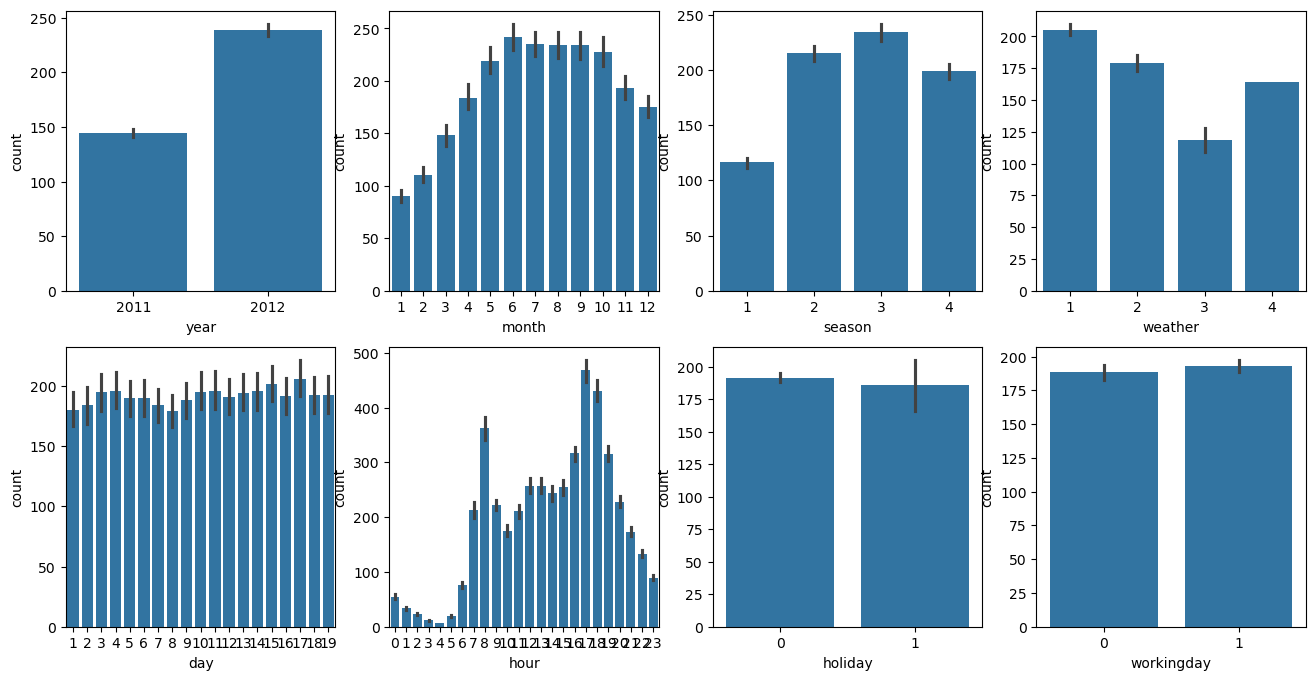

In [46]:
fig, axs = plt.subplots(figsize=(16, 8), ncols=4, nrows=2)
cat_features = ['year', 'month','season','weather','day', 'hour', 'holiday','workingday']
# cat_features에 있는 모든 칼럼별로 개별 칼럼값에 따른 count의 합을 barplot으로 시각화
for i, feature in enumerate(cat_features):
    row = int(i/4)
    col = i%4
    # 시본의 barplot을 이용해 칼럼값에 따른 count의 합을 표현
    sns.barplot(x=feature, y='count', data=bike_df, ax=axs[row][col])
plt.show()

- **year(년도)**: 2012년이 2011년보다 상대적으로 값이 높음 → year 자체에 특별한 의미가 있다기보다는 시간이 지날수록 자전거 대여 횟수가 지속적으로 증가한 결과로 여겨짐
- **month(월별)**: 1, 2, 3월이 낮고 6, 7, 8, 9월이 높음
- **season(계절)**: 봄(1), 겨울(4)이 낮고 여름(2), 가을(3)이 높음
- **weather(날씨)**: 눈 또는 비가 있는 경우(3과 4)가 낮고, 맑거나(1) 약간 안개가 있는 경우(2)가 높음
- **hour(시간)**: 오전 출근 시간(8)과 오후 퇴근 시간(17, 18)이 상대적으로 높음
- **day(일자)**: 일자 간 차이는 크지 않음
- **holiday(휴일 여부) / workingday(주중 여부)**: 주중일 경우(holiday는 0, workingday는 1)가 상대적으로 약간 높음

---
- 다양한 회귀 모델을 적용해 예측 성능을 측정함
- 캐글에서 요구한 성능 평가 방법은 **RMSLE(Root Mean Square Log Error)** = 오류 값의 로그에 대한 RMSE임
- 사이킷런은 RMSLE를 제공하지 않음 → RMSLE를 수행하는 성능 평가 함수를 직접 만듦 + RMSLE, MAE, RMSE를 한꺼번에 평가하는 함수도 만듦

In [47]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

# log 값 변환 시 NaN 등의 이슈로 log()가 아닌 log1p()를 이용해 RMSLE 계산
def rmsle(y, pred):
    log_y = np.log1p(y)
    log_pred = np.log1p(pred)
    squared_error = (log_y - log_pred) ** 2
    rmsle = np.sqrt(np.mean(squared_error))
    return rmsle

# 사이킷런의 mean_square_error()를 이용해 RMSE 계산
def rmse(y, pred):
    return np.sqrt(mean_squared_error(y, pred))

# MAE, RMSE, RMSLE를 모두 계산
def evaluate_regr(y, pred):
    rmsle_val = rmsle(y, pred)
    rmse_val = rmse(y, pred)
    # MAE는 사이킷런의 mean_absolute_error()로 계산
    mae_val = mean_absolute_error(y, pred)
    print('RMSLE: {0:.3f}, RMSE: {1:.3F}, MAE: {2:.3F}'.format(rmsle_val, rmse_val, mae_val))

- `rmsle()` 함수를 만들 때 주의할 점: 넘파이의 `log()` 함수나 사이킷런의 `mean_squared_log_error()`를 이용할 수도 있지만 데이터 값의 크기에 따라 **오버플로/언더플로(overflow/underflow) 오류**가 발생하기 쉬움
- 예를 들어 다음과 같이 정의하면 쉽게 오류가 발생할 수 있음 

```python
# 다음과 같은 rmsle 구현은 오버플로나 언더플로 오류를 발생시킬 수 있음
def rmsle(y, pred):
    msle = mean_squared_log_error(y, pred)
    rmsle = np.sqrt(mse)
    return rmsle
```

- 따라서 `log()`보다는 **`log1p()`**를 이용함
  - `log1p(x)`는 `log(1+x)`로 변환되므로 x값이 0이 되더라도 log(0)인 무한대가 되지 않고 log(1)인 0이 됨 → 오버플로/언더플로 문제 해결
  - `log1p()`로 변환된 값은 넘파이의 **`expm1()`** 함수로 쉽게 원래 스케일로 복원 가능함

### 로그 변환, 피처 인코딩과 모델 학습/예측/평가 
- 회귀 모델을 적용하기 전에 먼저 처리해야 할 사항 2가지
  1. **결괏값이 정규 분포로 돼 있는지** 확인
  2. 카테고리형 회귀 모델의 경우 **원-핫 인코딩으로 피처를 인코딩**
- 먼저 사이킷런의 LinearRegression 객체를 이용해 회귀 예측함

In [48]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso

y_target = bike_df['count']
X_features = bike_df.drop(['count'], axis=1, inplace=False)

X_train, X_test, y_train, y_test = train_test_split(X_features, y_target, test_size=0.3,
                                                    random_state=0)

lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
pred = lr_reg.predict(X_test)

evaluate_regr(y_test, pred)

RMSLE: 1.165, RMSE: 140.900, MAE: 105.924


- 실제 Target 데이터 값인 대여 횟수(Count)를 감안하면 예측 오류로서는 비교적 큰 값임
- 실제 값과 예측값이 어느 정도 차이가 나는지 DataFrame 칼럼으로 만들어 **오류 값이 가장 큰 순으로 5개**만 확인함

In [49]:
def get_top_error_data(y_test, pred, n_tops = 5):
    # DataFrame의 칼럼으로 실제 대여 횟수(count)와 예측값을 서로 비교할 수 있도록 생성.
    result_df = pd.DataFrame(y_test.values, columns=['real_count'])
    result_df['predicted_count']= np.round(pred)
    result_df['diff'] = np.abs(result_df['real_count'] - result_df['predicted_count'])
    # 예측값과 실제 값이 가장 큰 데이터 순으로 출력.
    print(result_df.sort_values('diff', ascending=False)[:n_tops])

get_top_error_data(y_test, pred, n_tops=5)

      real_count  predicted_count   diff
1618         890            322.0  568.0
3151         798            241.0  557.0
966          884            327.0  557.0
412          745            194.0  551.0
2817         856            310.0  546.0


- 가장 큰 상위 5위 오류 값은 **546~568**로 실제 값을 감안하면 예측 오류가 꽤 큼
- 회귀에서 큰 예측 오류가 발생할 경우 가장 먼저 살펴볼 것: **Target 값의 분포가 왜곡된 형태인지** 확인
  - Target 값의 분포는 **정규 분포 형태가 가장 좋음**, 왜곡된 경우 회귀 예측 성능이 저하되기 쉬움
- 판다스 DataFrame의 `hist()`로 count 칼럼이 정규 분포를 이루는지 확인함

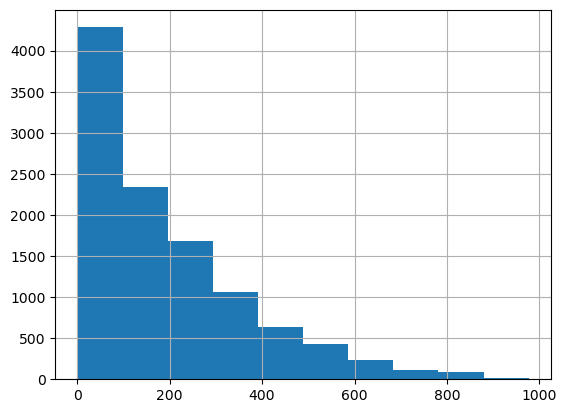

In [50]:
y_target.hist()
plt.show()

- count 칼럼 값이 정규 분포가 아닌 **0~200 사이에 왜곡**돼 있음
- 왜곡된 값을 정규 분포 형태로 바꾸는 가장 일반적인 방법 = **로그를 적용해 변환**
  - 넘파이의 `log1p()` 이용 → 변경된 Target 값으로 학습하고, 예측한 값은 다시 `expm1()` 함수로 원래 scale 값으로 원상 복구함
- `log1p()`를 적용한 'count' 값의 분포를 확인함

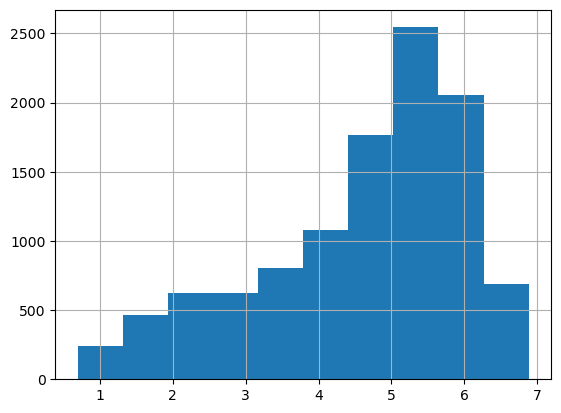

In [51]:
y_log_transform = np.log1p(y_target)
y_log_transform.hist()
plt.show()

- 로그로 Target 값을 변환한 후 원하는 정규 분포 형태는 아니지만 변환 전보다는 **왜곡 정도가 많이 향상**됨
- 이를 이용해 다시 학습한 후 평가 수행함

In [52]:
# 타깃 칼럼인 count 값을 log1p로 로그 변환
y_target_log = np.log1p(y_target)

# 로그 변환된 y_target_log를 반영해 학습/테스트 데이터 세트 분할
X_train, X_test, y_train, y_test = train_test_split(X_features, y_target_log, test_size=0.3,
                                                    random_state=0)
lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
pred = lr_reg.predict(X_test)

# 테스트 데이터 세트의 Target 값은 로그 변환됐으므로 다시 expm1을 이용해 원래 스케일로 변환
y_test_exp = np.expm1(y_test)

# 예측값 역시 로그 변환된 타깃 기반으로 학습돼 예측됐으므로 다시 expm1로 스케일 변환
pred_exp = np.expm1(pred)

evaluate_regr(y_test_exp, pred_exp)

RMSLE: 1.017, RMSE: 162.594, MAE: 109.286


- **RMSLE 오류는 줄어들었지만, RMSE는 오히려 더 늘어남**
- 이번에는 개별 피처들의 인코딩을 적용해 봄 → 먼저 각 피처의 회귀 계숫값을 시각화함

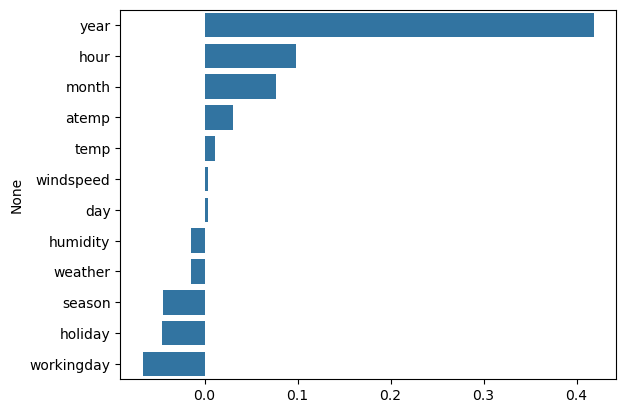

In [53]:
coef = pd.Series(lr_reg.coef_, index=X_features.columns)
coef_sort = coef.sort_values(ascending=False)
sns.barplot(x=coef_sort.values, y=coef_sort.index)
plt.show()

- year, hour, month, season, holiday, workingday 피처들의 회귀 계수 영향도가 상대적으로 높음
- 이 피처들은 year는 2011, 2012 값으로, month는 1~12와 같이 **숫잣값 형태로 의미**를 담고 있음
  - 하지만 개별 숫잣값의 크기가 의미 있는 것이 아님 → Year는 단순히 연도를 뜻하므로 2012라는 값이 2011보다 큰 값으로 인식되면 안 됨
  - 즉 year, hour, month 등은 숫자 값으로 표현됐지만 모두 **카테고리(Category)형 피처**임
- 사이킷런은 카테고리만을 위한 데이터 타입이 없으며 모두 숫자로 변환해야 함
  - 숫자형 카테고리 값을 선형 회귀에 사용하면 회귀 계수 연산 시 이 숫자형 값에 크게 영향을 받는 경우가 발생할 수 있음
  - 따라서 **선형 회귀에서는 원-핫 인코딩**을 적용해 변환해야 함
- 판다스의 `get_dummies()`로 year, month, day, hour, holiday, workingday, season, weather 칼럼을 모두 원-핫 인코딩한 후 다시 예측 성능을 확인함

In [54]:
# 'year', month', 'day', hour'등의 피처들을 One Hot Encoding
X_features_ohe = pd.get_dummies(X_features, columns=['year', 'month','day', 'hour', 'holiday',
                                                     'workingday','season','weather'])

- 사이킷런의 선형 회귀 모델 LinearRegression, Ridge, Lasso 모두 학습해 예측 성능을 확인함
- 모델과 학습/테스트 데이터 세트를 입력하면 성능 평가 수치를 반환하는 `get_model_predict()` 함수를 만듦

In [55]:
# 원-핫 인코딩이 적용된 피처 데이터 세트 기반으로 학습/예측 데이터 분할.
X_train, X_test, y_train, y_test = train_test_split(X_features_ohe, y_target_log,
                                                    test_size=0.3, random_state=0)

# 모델과 학습/테스트 데이터 세트를 입력하면 성능 평가 수치를 반환
def get_model_predict(model, X_train, X_test, y_train, y_test, is_expm1=False):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    if is_expm1 :
        y_test = np.expm1(y_test)
        pred = np.expm1(pred)
    print('###',model.__class__.__name__,'###')
    evaluate_regr(y_test, pred)
# end of function get_model_predict

# 모델별로 평가 수행
lr_reg = LinearRegression()
ridge_reg = Ridge(alpha=10)
lasso_reg = Lasso(alpha=0.01)

for model in [lr_reg, ridge_reg, lasso_reg]:
    get_model_predict(model,X_train, X_test, y_train, y_test,is_expm1=True)

### LinearRegression ###
RMSLE: 0.590, RMSE: 97.688, MAE: 63.382
### Ridge ###
RMSLE: 0.590, RMSE: 98.529, MAE: 63.893
### Lasso ###
RMSLE: 0.635, RMSE: 113.219, MAE: 72.803


- (책 출력)

| 모델 | RMSLE | RMSE | MAE |
|---|---|---|---|
| LinearRegression | 0.590 | 97.688 | 63.382 |
| Ridge | 0.590 | 98.529 | 63.893 |
| Lasso | 0.635 | 113.219 | 72.803 |

- 원-핫 인코딩을 적용하고 나서 **선형 회귀의 예측 성능이 많이 향상**됨
- 원-핫 인코딩으로 피처가 늘어났으므로 회귀 계수 **상위 20개** 피처를 추출해 시각화함

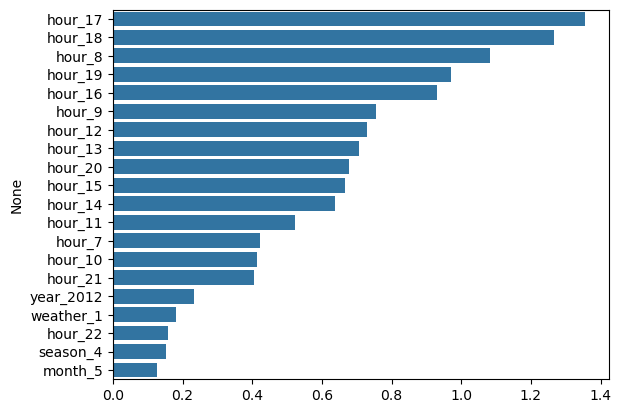

In [56]:
coef = pd.Series(lr_reg.coef_ , index=X_features_ohe.columns)
coef_sort = coef.sort_values(ascending=False)[:20]
sns.barplot(x=coef_sort.values , y=coef_sort.index)
plt.show()

- 원-핫 인코딩을 통해 피처들의 영향도가 달라졌고 모델의 성능도 향상됨
- 반드시 그런 것은 아니지만 선형 회귀의 경우 **중요 카테고리성 피처들을 원-핫 인코딩으로 변환하는 것은 성능에 중요한 영향**을 미칠 수 있음
---
- 이번에는 회귀 트리를 이용해 회귀 예측 수행함
- 앞에서 적용한 Target 값의 로그 변환된 값과 원-핫 인코딩된 피처 데이터 세트를 그대로 이용해 **랜덤 포레스트, GBM, XGBoost, LightGBM**을 순차적으로 성능 평가함
- XGBoost의 경우 DataFrame이 학습/테스트 데이터로 입력될 경우 버전에 따라 오류가 발생할 수 있음 → DataFrame의 `values` 속성으로 넘파이 ndarray로 변환함

In [57]:
!pip install xgboost lightgbm

In [58]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# 랜덤 포레스트, GBM, XGBoost, LightGBM model별로 평가 수행
rf_reg = RandomForestRegressor(n_estimators=500)
gbm_reg = GradientBoostingRegressor(n_estimators=500)
xgb_reg = XGBRegressor(n_estimators=500)
lgbm_reg = LGBMRegressor(n_estimators=500)

for model in [rf_reg, gbm_reg, xgb_reg, lgbm_reg]:
    # XGBoost의 경우 DataFrame이 입력될 경우 버전에 따라 오류 발생 가능. ndarray로 변환.
    get_model_predict(model,X_train.values, X_test.values, y_train.values,
                      y_test.values,is_expm1=True)

### RandomForestRegressor ###
RMSLE: 0.354, RMSE: 50.229, MAE: 31.067
### GradientBoostingRegressor ###
RMSLE: 0.330, RMSE: 53.321, MAE: 32.733
### XGBRegressor ###
RMSLE: 0.339, RMSE: 51.475, MAE: 31.357
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000155 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 348
[LightGBM] [Info] Number of data points in the train set: 7620, number of used features: 72
[LightGBM] [Info] Start training from score 4.582043
### LGBMRegressor ###
RMSLE: 0.319, RMSE: 47.215, MAE: 29.029



- 앞의 선형 회귀 모델보다 회귀 예측 성능이 개선됨
- 하지만 이것이 회귀 트리가 선형 회귀보다 더 나은 성능을 가진다는 의미는 아님 → **데이터 세트의 유형에 따라 결과는 얼마든지 달라질 수 있음**

## 10 회귀 실습 - 캐글 주택 가격: 고급 회귀 기법

- 캐글의 주택 가격: 고급 회귀 기법(House Prices: Advanced Regression Techniques) 데이터 세트로 회귀 분석을 더 심층적으로 학습함
- 데이터: https://www.kaggle.com/c/house-prices-advanced-regression-techniques/data 에서 **train.csv**를 내려받은 후 **house_price.csv로 저장**함 
- **79개의 변수**로 구성, 미국 아이오와 주의 에임스(Ames) 지방의 주택 가격 정보
- 성능 평가는 자전거 대여 예측과 동일한 **RMSLE(Root Mean Squared Log Error)** 기반
  - 캐글 웹 페이지에는 'RMSE를 하되 예측값과 실제 값의 로그 변환 값을 기반으로 RMSE를 수행'한다고 돼 있음 → 결론적으로 RMSLE와 똑같은 방식임
  - 가격이 비싼 주택일수록 예측 결과 오류가 전체 오류에 미치는 비중이 높으므로 이를 상쇄하기 위해 오류 값을 로그 변환한 RMSLE를 이용함

In [59]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

house_df_org = pd.read_csv('/Users/sumin/desktop/python/ESAA/data/house-prices-advanced-regression-techniques/house_price.csv')
house_df = house_df_org.copy()
house_df.head(3)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500


- Target 값은 맨 마지막 칼럼인 **SalePrice**임
- 데이터 세트의 전체 크기와 칼럼의 타입, Null이 있는 칼럼과 그 건수를 내림차순으로 출력함

In [60]:
print('데이터 세트의 Shape:', house_df.shape)
print('\n전체 피처의 type \n', house_df.dtypes.value_counts())
isnull_series = house_df.isnull().sum()
print('\nNull 칼럼과 그 건수:\n ', isnull_series[isnull_series > 0].sort_values(ascending=False))

데이터 세트의 Shape: (1460, 81)

전체 피처의 type 
 object     43
int64      35
float64     3
Name: count, dtype: int64

Null 칼럼과 그 건수:
  PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtFinType1      37
BsmtCond          37
BsmtQual          37
MasVnrArea         8
Electrical         1
dtype: int64


- **1460개 레코드와 81개 피처**로 구성, 피처 타입은 숫자형은 물론 문자형도 많음
  - Target을 제외한 80개 피처 중 **43개가 문자형**이며 나머지가 숫자형임
- 데이터 양에 비해 Null 값이 많은 피처도 있음 → 전체 1480개 데이터 중 PoolQC, MiscFeature, Alley, Fence는 **1000개가 넘는 데이터가 Null**임 
  - Null 값이 너무 많은 피처는 **드롭**함
- 회귀 모델 적용 전에 타깃 값의 분포도가 정규 분포인지 확인함 → 데이터 값의 분포가 중심에서 **왼쪽으로 치우친 형태**로 정규 분포에서 벗어나 있음

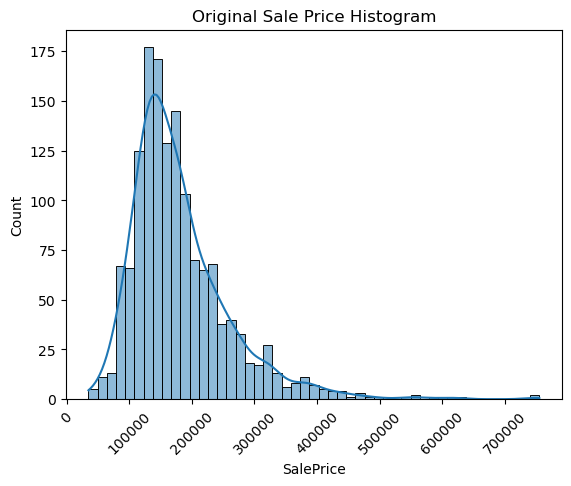

In [61]:
plt.title('Original Sale Price Histogram')
plt.xticks(rotation=45)
sns.histplot(house_df['SalePrice'], kde=True)
plt.show()

- 정규 분포가 아닌 결괏값을 정규 분포 형태로 변환하기 위해 **로그 변환(Log Transformation)** 적용
  - 넘파이의 `log1p()`로 로그 변환한 결괏값을 기반으로 학습 → 예측 시에는 다시 결괏값을 `expm1()`으로 환원하면 됨
- 결괏값을 로그 변환하고 다시 분포도를 살펴봄

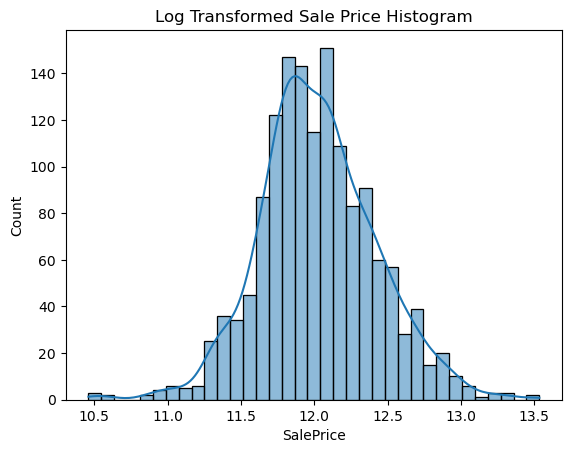

In [62]:
plt.title('Log Transformed Sale Price Histogram')
log_SalePrice = np.log1p(house_df['SalePrice'])
sns.histplot(log_SalePrice, kde=True)
plt.show()

- SalePrice를 로그 변환해 **정규 분포 형태로 결괏값이 분포**함을 확인할 수 있음 → SalePrice를 로그 변환한 뒤 DataFrame에 반영함
- Null 값이 많은 피처인 **PoolQC, MiscFeature, Alley, Fence, FireplaceQu는 삭제**함, **Id**도 단순 식별자이므로 삭제함
- **LotFrontage**는 Null이 259개로 비교적 많으나 **평균값으로 대체**함
- 나머지 Null 피처는 Null 값이 많지 않으므로 **숫자형의 경우 평균값으로 대체**함
- DataFrame 객체의 `mean()` 메서드는 자동으로 숫자형 칼럼만 추출해 칼럼별 평균값을 Series 객체로 반환함 → `DataFrame.fillna(DataFrame.mean())`은 결과적으로 Null 값인 숫자형 피처만 평균값으로 대체함

In [63]:
# SalePrice 로그 변환
original_SalePrice = house_df['SalePrice']
house_df['SalePrice'] = np.log1p(house_df['SalePrice'])

# Null이 너무 많은 칼럼과 불필요한 칼럼 삭제
house_df.drop(['Id', 'PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu'],axis=1, inplace=True)

# 드롭하지 않은 숫자형 Null 칼럼은 평균값으로 대체
numerical_cols = house_df.select_dtypes(include=np.number).columns
house_df[numerical_cols] = house_df[numerical_cols].fillna(house_df[numerical_cols].mean())

# Null 값이 있는 피처명과 타입을 추출
null_column_count = house_df.isnull().sum()[house_df.isnull().sum() >0]
print('## Null 피처의 Type: \n', house_df.dtypes[null_column_count.index])


## Null 피처의 Type: 
 MasVnrType      object
BsmtQual        object
BsmtCond        object
BsmtExposure    object
BsmtFinType1    object
BsmtFinType2    object
Electrical      object
GarageType      object
GarageFinish    object
GarageQual      object
GarageCond      object
dtype: object


- 이제 **문자형 피처를 제외하고는 Null 값이 없음** → 문자형 피처는 모두 원-핫 인코딩으로 변환함 (판다스 `get_dummies()`)
- `get_dummies()`는 자동으로 문자열 피처를 원-핫 인코딩 변환하면서 **Null 값은 모든 인코딩 값이 0으로 변환**되는 방식으로 대체해 주므로 별도의 Null 값 대체 로직이 필요 없음
  - 예: BsmtQual 칼럼값이 'TA', 'Gd', 'Ex', 'FA' 외에 Null 값이 존재하면 Null은 [0, 0, 0, 0]과 같이 BsmtQual의 4개 종류로 만들어진 인코딩 값을 모두 0으로 하여 원-핫 인코딩 변환됨 (4개의 값 중 반드시 1개는 1이 되는 일반적인 원-핫 인코딩과 다르게 변환됨)
- 원-핫 인코딩을 적용하면 당연히 칼럼이 증가함 → 얼마나 늘어났는지 확인함

In [64]:
print('get_dummies() 수행 전 데이터 Shape:', house_df.shape)
house_df_ohe = pd.get_dummies(house_df)
print('get_dummies() 수행 후 데이터 Shape:', house_df_ohe.shape)

null_column_count = house_df_ohe.isnull().sum()[house_df_ohe.isnull().sum() > 0]
print('## Null 피처의 Type :\n', house_df_ohe.dtypes[null_column_count.index])

get_dummies() 수행 전 데이터 Shape: (1460, 75)
get_dummies() 수행 후 데이터 Shape: (1460, 270)
## Null 피처의 Type :
 Series([], dtype: object)


- (책 출력) 수행 전 Shape: (1460, 75) / 수행 후 Shape: (1460, 271) / Null 피처의 Type: `Series([], dtype: object)`
- 원-핫 인코딩 후 피처가 **75개 → 271개**로 증가, Null 값을 가진 피처는 이제 존재하지 않음
- 데이터 세트의 기본 가공은 마침 → 학습/테스트 데이터 세트로 분할해 LinearRegression, Ridge, Lasso로 선형 계열 회귀 모델을 만듦

### 선형 회귀 모델 학습/예측/평가
- 예측 평가는 RMSLE(실제 값과 예측값의 오류를 로그 변환한 뒤 RMSE 적용)를 이용함
- 이미 타깃 값인 SalePrice가 로그 변환됨 → 예측값 역시 로그 변환된 SalePrice 기반으로 예측하므로 원본 SalePrice 예측값의 로그 변환 값임
  - 실제 값도 로그 변환됐고 예측값도 로그 변환 값이므로 **예측 결과 오류에 RMSE만 적용하면 RMSLE가 자동으로 측정**됨
- 여러 모델의 로그 변환된 RMSE를 측정할 것이므로 이를 계산하는 함수를 먼저 생성함

In [65]:
def get_rmse(model):
    pred = model.predict(X_test)
    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)
    print(model.__class__.__name__, ' 로그 변환된 RMSE:', np.round(rmse, 3))
    return rmse

def get_rmses(models):
    rmses = [ ]
    for model in models:
        rmse = get_rmse(model)
        rmses.append(rmse)
    return rmses

- `get_rmse(model)`은 단일 모델의 RMSE 값을, `get_rmses(models)`는 `get_rmse()`를 이용해 여러 모델의 RMSE 값을 반환함
- 이제 선형 회귀 모델을 학습하고 예측, 평가함

In [66]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

y_target = house_df_ohe['SalePrice']
X_features = house_df_ohe.drop('SalePrice', axis=1, inplace=False)
X_train, X_test, y_train, y_test = train_test_split(X_features, y_target, test_size=0.2,
                                                    random_state=156)

# LinearRegression, Ridge, Lasso 학습, 예측, 평가
lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
ridge_reg = Ridge()
ridge_reg.fit(X_train, y_train)
lasso_reg = Lasso()
lasso_reg.fit(X_train, y_train)

models = [lr_reg, ridge_reg, lasso_reg]
get_rmses(models)

LinearRegression  로그 변환된 RMSE: 0.132
Ridge  로그 변환된 RMSE: 0.127
Lasso  로그 변환된 RMSE: 0.176


[np.float64(0.13183184688250477),
 np.float64(0.127405828362661),
 np.float64(0.17628250556471398)]

- **라쏘 회귀**의 경우 회귀 성능이 타 회귀 방식보다 많이 떨어짐 → 최적 하이퍼 파라미터 튜닝이 필요해 보임 
- 먼저 피처별 회귀 계수를 시각화해 모델별로 어떠한 피처의 회귀 계수로 구성되는지 확인함
- 피처가 많으니 회귀 계수 값의 **상위 10개, 하위 10개**의 피처명과 회귀 계수 값을 가지는 판다스 Series 객체를 반환하는 함수를 만듦

In [70]:
def get_top_bottom_coef(model, n=10):
    # coef_ 속성을 기반으로 Series 객체를 생성. index는 칼럼명.
    coef = pd.Series(model.coef_, index=X_features.columns)

    # + 상위 10개, - 하위 10개의 회귀 계수를 추출해 반환.
    coef_high = coef.sort_values(ascending=False).head(n)
    coef_low = coef.sort_values(ascending=False).tail(n)
    return coef_high, coef_low

- `get_top_bottom_coef(model, n=10)` 함수를 이용해 모델별 회귀 계수를 시각화함
- 시각화 함수 `visualize_coefficient(models)`: list 객체로 모델을 입력받아 모델별로 회귀 계수 상위 10개, 하위 10개를 추출해 **가로 막대 그래프** 형태로 출력함

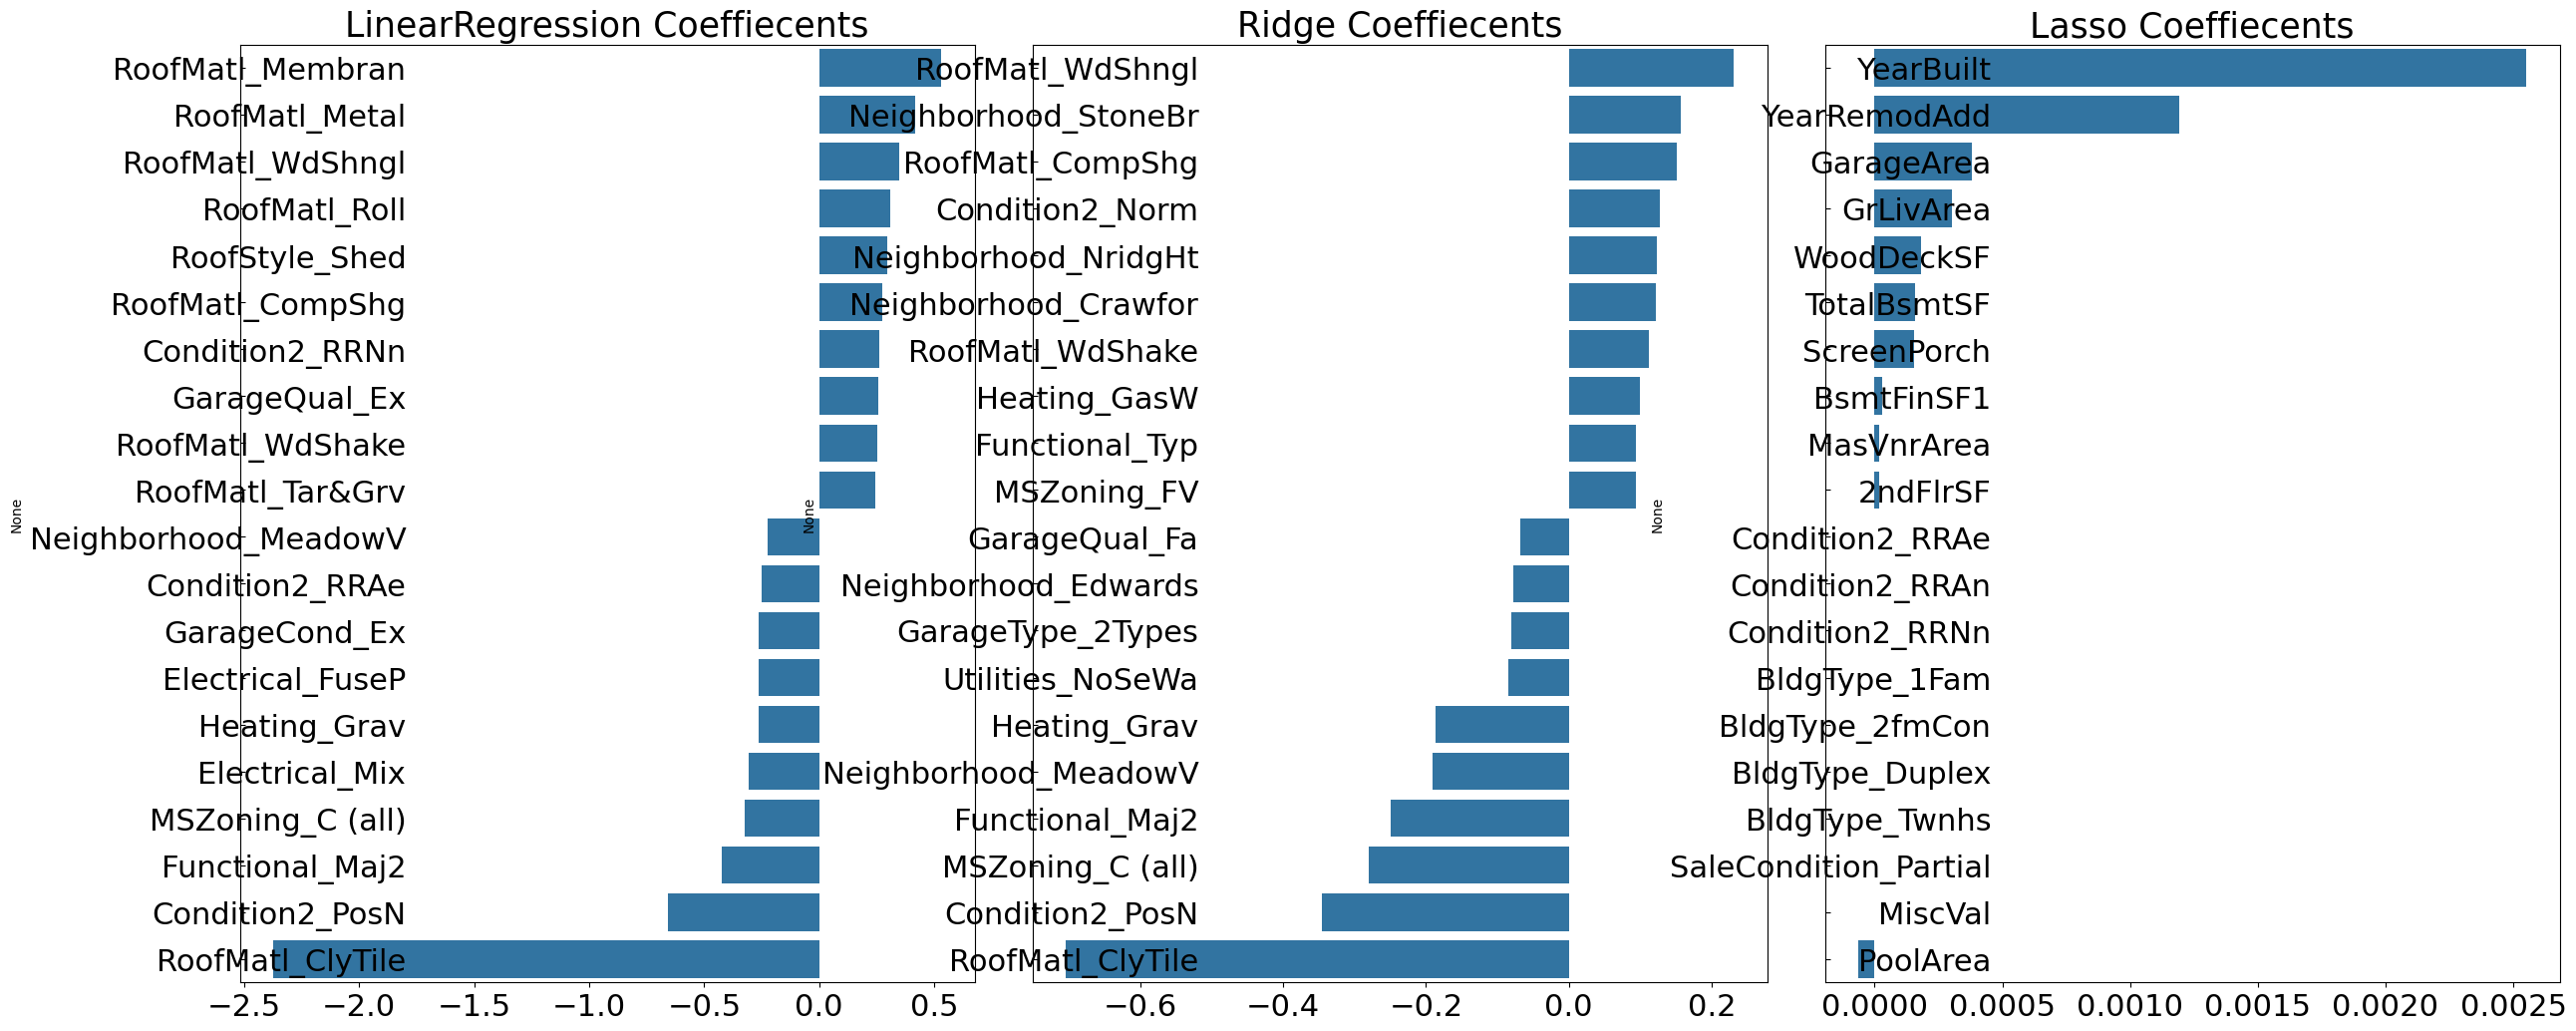

In [76]:
def visualize_coefficient(models):
    # 3개 회귀 모델의 시각화를 위해 3개의 칼럼을 가지는 subplot 생성
    fig, axs = plt.subplots(figsize=(24, 10), nrows=1, ncols=3)
    fig.tight_layout()
    # 입력 인자로 받은 list 객체인 models에서 차례로 model을 추출해 회귀 계수 시각화.
    for i_num, model in enumerate(models):
        # 상위 10개, 하위 10개 회귀 계수를 구하고, 이를 판다스 concat으로 결합
        coef_high, coef_low = get_top_bottom_coef(model)
        coef_concat = pd.concat( [coef_high, coef_low] )
        # ax subplot에 barchar로 표현. 한 화면에 표현하기 위해 tick label 위치와 font 크기 조정.
        axs[i_num].set_title(model.__class__.__name__+' Coeffiecents', size=25)
        axs[i_num].tick_params(axis="y", direction="in", pad=-120)
        for label in (axs[i_num].get_xticklabels() + axs[i_num].get_yticklabels()):
            label.set_fontsize(22)
        sns.barplot(x=coef_concat.values, y=coef_concat.index, ax=axs[i_num])


# 앞 예제에서 학습한 lr_reg, ridge_reg, lasso_reg 모델의 회귀 계수 시각화.
models = [lr_reg, ridge_reg, lasso_reg]
visualize_coefficient(models)
plt.show()

- **OLS 기반의 LinearRegression과 Ridge**는 회귀 계수가 유사한 형태로 분포함
- **라쏘(Lasso)**는 전체적으로 회귀 계수 값이 매우 작고, 그중에 YearBuilt가 가장 크고 다른 피처의 회귀 계수는 너무 작음 → 다른 두 모델과 다른 회귀 계수 형태를 보임
- 학습 데이터의 분할에 문제가 있어서 그런 것인지 확인하기 위해, train_test_split()으로 분할하지 않고 **전체 데이터 세트인 X_features와 y_target을 5개의 교차 검증 폴드 세트로 분할**해 평균 RMSE를 측정함 → `cross_val_score()` 이용

In [77]:
from sklearn.model_selection import cross_val_score

def get_avg_rmse_cv(models):

    for model in models:
        # 분할하지 않고 전체 데이터로 cross_val_score( ) 수행. 모델별 CV RMSE값과 평균 RMSE 출력
        rmse_list = np.sqrt(-cross_val_score(model, X_features, y_target,
                                             scoring="neg_mean_squared_error", cv = 5))
        rmse_avg = np.mean(rmse_list)
        print('\n{0} CV RMSE 값 리스트: {1}'.format(model.__class__.__name__, np.round(rmse_list, 3)))
        print('{0} CV 평균 RMSE 값: {1}'.format(model.__class__.__name__, np.round(rmse_avg, 3)))

# 앞 예제에서 학습한 ridge_reg, lasso_reg 모델의 CV RMSE값 출력
models = [ridge_reg, lasso_reg]
get_avg_rmse_cv(models)


Ridge CV RMSE 값 리스트: [0.117 0.154 0.142 0.117 0.189]
Ridge CV 평균 RMSE 값: 0.144

Lasso CV RMSE 값 리스트: [0.161 0.204 0.177 0.181 0.265]
Lasso CV 평균 RMSE 값: 0.198


- 5개 폴드 세트로 학습한 후 평가해도 **여전히 라쏘가 릿지 모델보다 성능이 떨어짐**
- 릿지와 라쏘 모델에 대해 **alpha 하이퍼 파라미터**를 변화시키면서 최적 값을 도출함
- 모델별 최적화 하이퍼 파라미터 작업을 반복하므로 별도 함수 생성 → `print_best_params(model, params)`: 모델과 하이퍼 파라미터 딕셔너리 객체를 받아 최적화 작업의 결과를 표시함

In [78]:
from sklearn.model_selection import GridSearchCV

def print_best_params(model, params):
    grid_model = GridSearchCV(model, param_grid=params,
                              scoring='neg_mean_squared_error', cv=5)
    grid_model.fit(X_features, y_target)
    rmse = np.sqrt(-1* grid_model.best_score_)
    print('{0} 5 CV 시 최적 평균 RMSE 값:{1}, 최적 alpha:{2}'.format(model.__class__.__name__,
                                        np.round(rmse, 4), grid_model.best_params_))

ridge_params = { 'alpha':[0.05, 0.1, 1, 5, 8, 10, 12, 15, 20] }
lasso_params = { 'alpha':[0.001, 0.005, 0.008, 0.05, 0.03, 0.1, 0.5, 1, 5, 10] }
print_best_params(ridge_reg, ridge_params)
print_best_params(lasso_reg, lasso_params)

Ridge 5 CV 시 최적 평균 RMSE 값:0.1418, 최적 alpha:{'alpha': 12}
Lasso 5 CV 시 최적 평균 RMSE 값:0.142, 최적 alpha:{'alpha': 0.001}


- 릿지는 **alpha=12**에서 최적 평균 RMSE **0.1418**, 라쏘는 **alpha=0.001**에서 최적 평균 RMSE **0.142**
- 라쏘 모델의 경우 alpha 값 최적화 이후 예측 성능이 많이 좋아짐
- 선형 모델에 최적 alpha 값을 설정한 뒤 train_test_split()으로 분할된 학습/테스트 데이터로 학습/예측/평가를 수행하고 모델별 회귀 계수를 시각화함

LinearRegression  로그 변환된 RMSE: 0.132
Ridge  로그 변환된 RMSE: 0.124
Lasso  로그 변환된 RMSE: 0.12


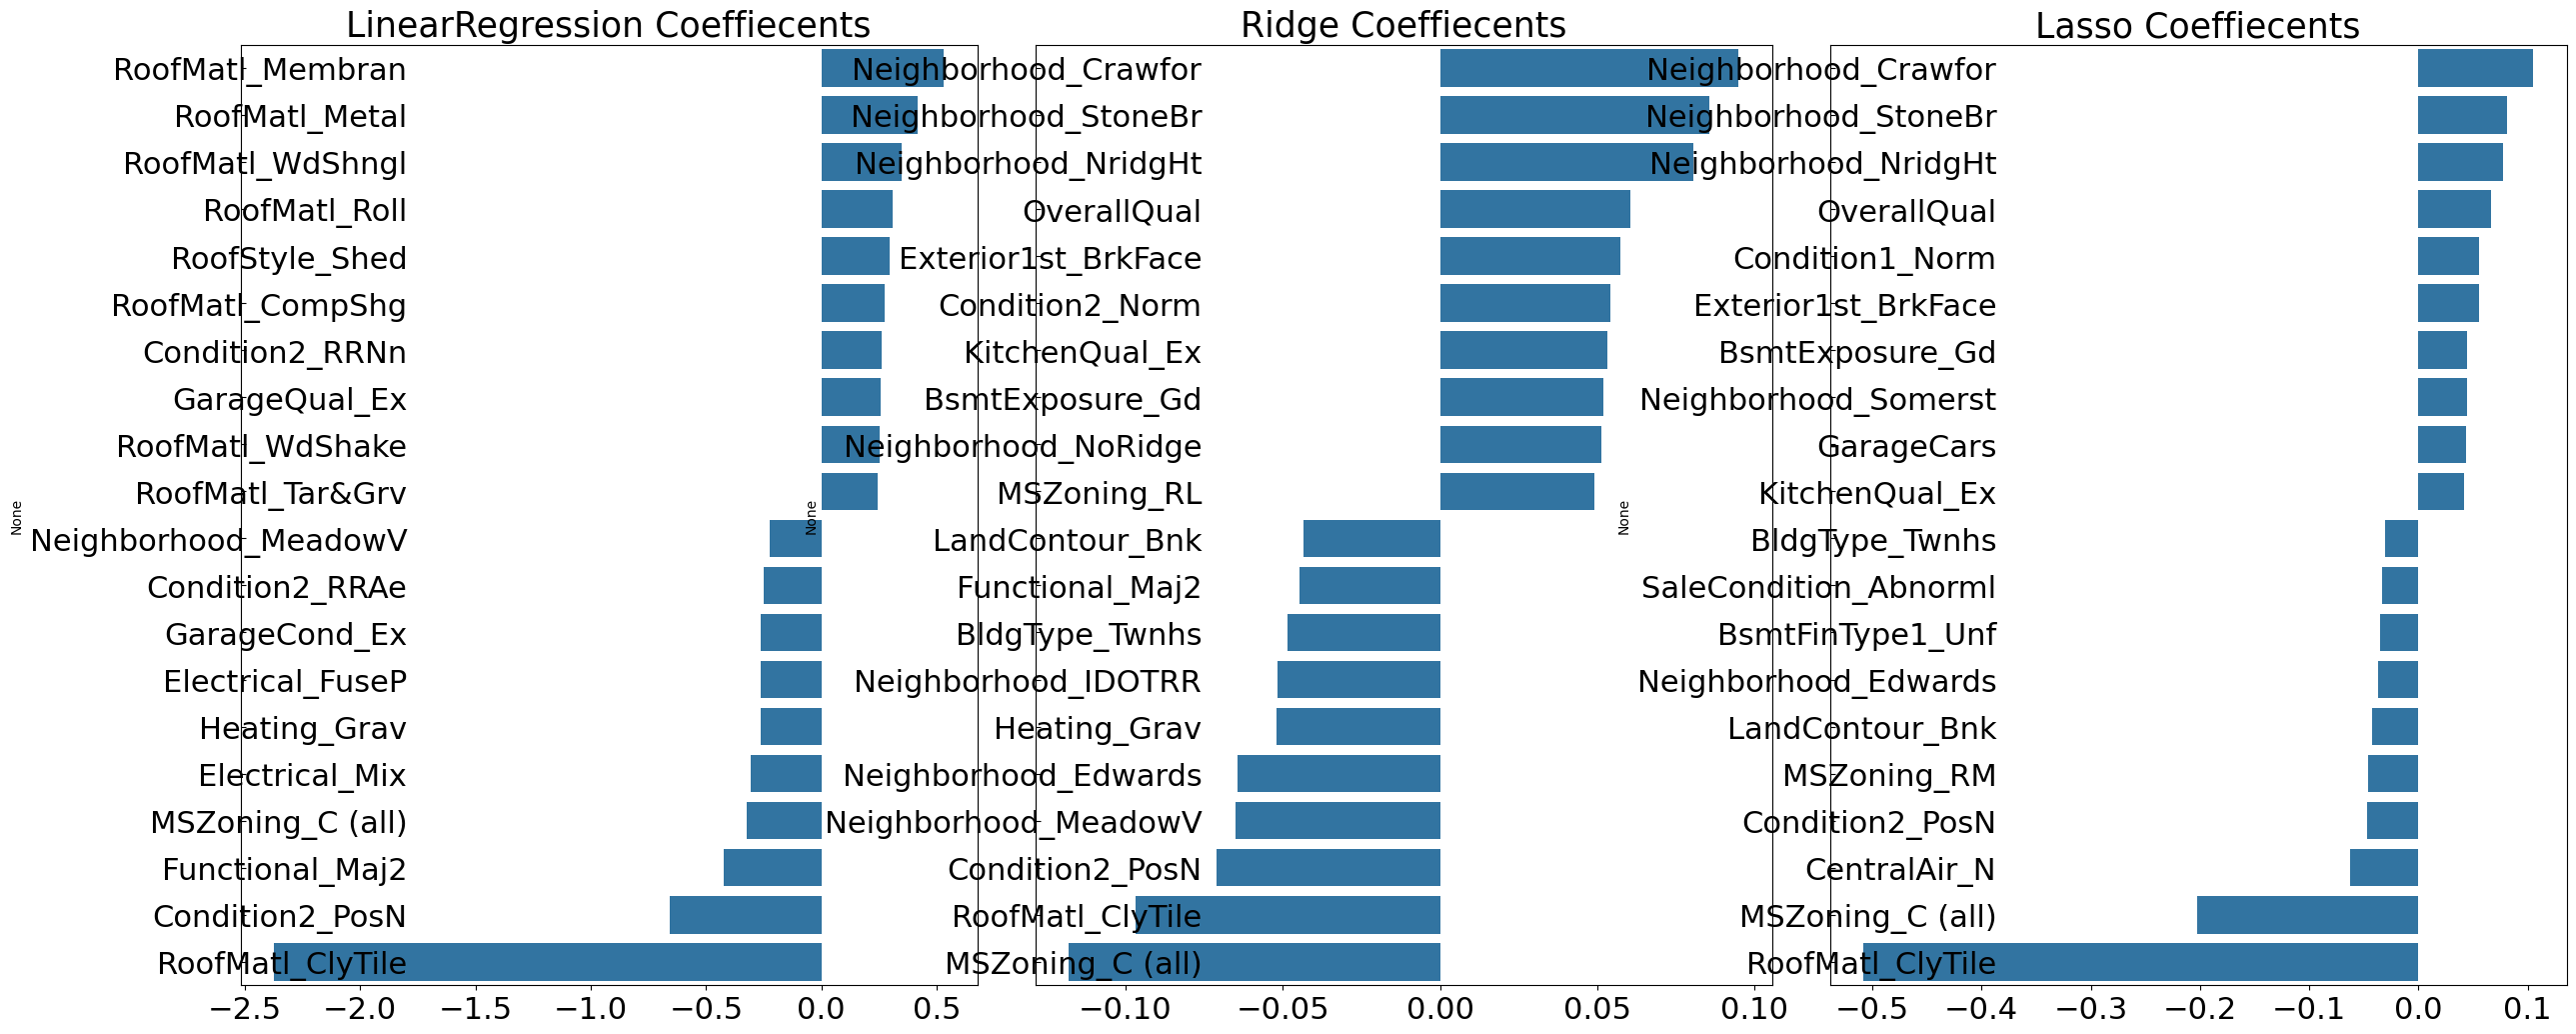

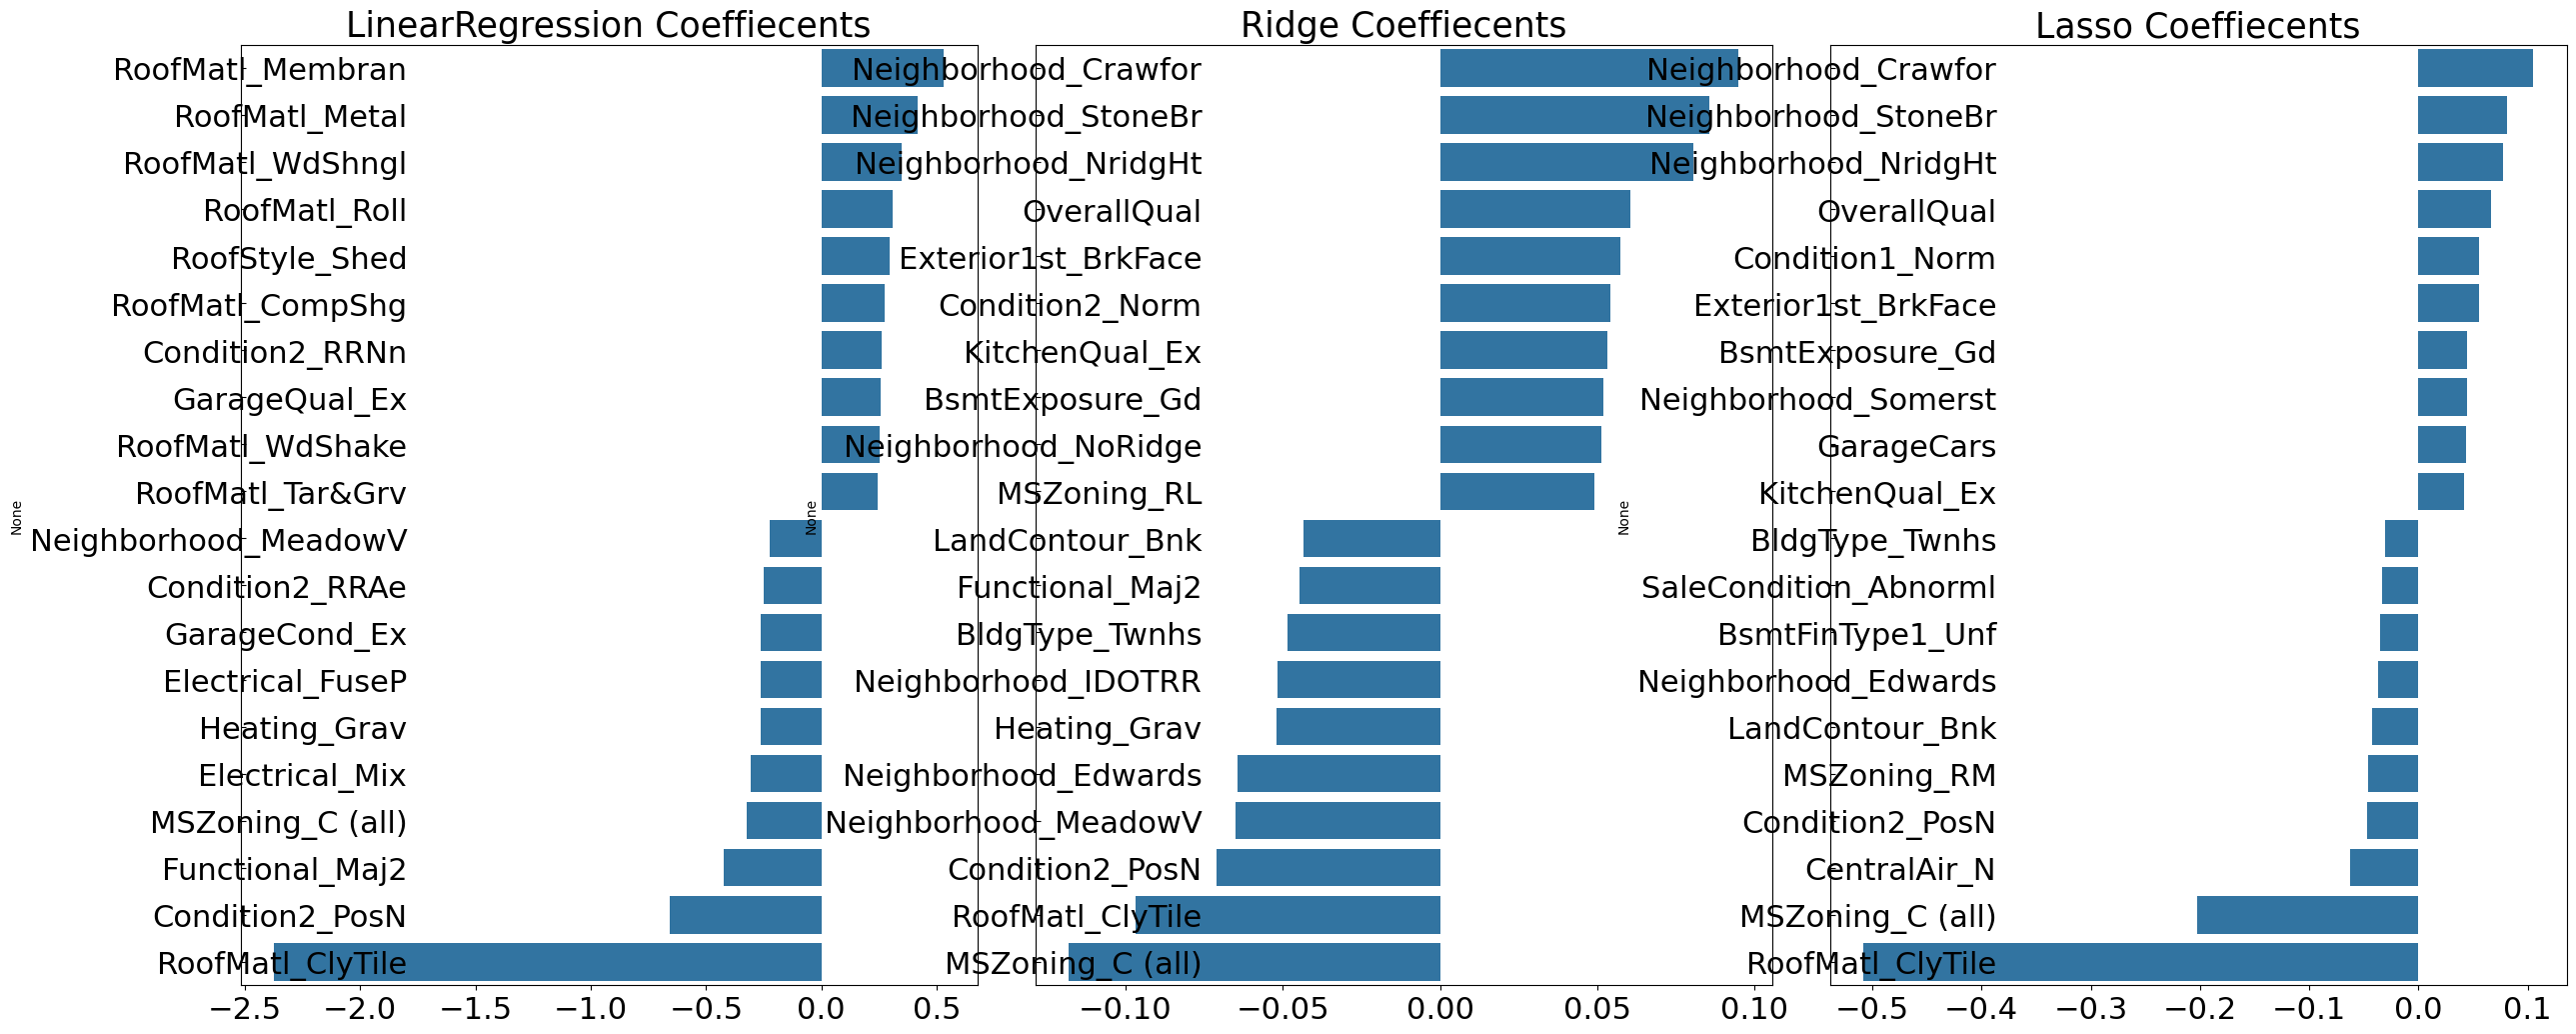

In [82]:
# 앞의 최적화 alpha 값으로 학습 데이터로 학습, 테스트 데이터로 예측 및 평가 수행.
lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
ridge_reg = Ridge(alpha=12)
ridge_reg.fit(X_train, y_train)
lasso_reg = Lasso(alpha=0.001)
lasso_reg.fit(X_train, y_train)

# 모든 모델의 RMSE 출력
models = [lr_reg, ridge_reg, lasso_reg]
get_rmses(models)

# 모든 모델의 회귀 계수 시각화
models = [lr_reg, ridge_reg, lasso_reg]
visualize_coefficient(models)
plt.show()

- alpha 값 최적화 후 테스트 데이터 세트의 **예측 성능이 더 좋아짐**, 모델별 회귀 계수도 많이 달라짐
- 기존에는 라쏘의 회귀 계수가 나머지 두 모델과 많은 차이가 있었지만, 이번에는 **릿지와 라쏘에서 비슷한 피처의 회귀 계수가 높음**
  - 다만 라쏘는 릿지에 비해 동일한 피처라도 회귀 계수의 값이 상당히 작음

---
- 데이터 세트를 추가로 가공해 모델 튜닝을 더 진행함: ① **피처 데이터 세트의 데이터 분포도**, ② **이상치(Outlier) 데이터 처리**
- 피처 데이터 세트도 지나치게 왜곡된 피처가 존재하면 회귀 예측 성능을 저하시킬 수 있음 → 모든 숫자형 피처의 분포도가 어느 정도로 왜곡됐는지 알아봄
- 사이파이 stats 모듈의 **`skew()`** 함수로 칼럼 데이터 세트의 왜곡된 정도를 쉽게 추출할 수 있음
  - 일반적으로 skew() 반환 값이 **1 이상**인 경우 왜곡 정도가 높다고 판단함(상황에 따라 편차는 있음)
  - 여기서는 1 이상의 값을 반환하는 피처만 추출해 왜곡 정도를 완화하기 위해 **로그 변환** 적용
  - 숫자형 피처의 칼럼 index 객체를 추출해 구한 숫자형 칼럼 데이터 세트의 apply lambda 식으로 skew()를 호출함
- 주의: skew()를 적용하는 숫자형 피처에서 **원-핫 인코딩된 카테고리 숫자형 피처는 제외**해야 함
  - 카테고리 피처는 코드성 피처이므로 인코딩 시 당연히 왜곡될 가능성이 높음 (예: '화장실 여부'가 1로 1000건, 0으로 10건 → 왜곡과는 무관함)
  - 따라서 skew() 함수를 적용하는 DataFrame은 원-핫 인코딩이 적용된 house_df_ohe가 아니라 **원-핫 인코딩이 적용되지 않은 house_df**여야 함

In [83]:
from scipy.stats import skew

# object가 아닌 숫자형 피처의 칼럼 index 객체 추출.
features_index = house_df.dtypes[house_df.dtypes != 'object'].index
# house_df에 칼럼 index를 [ ]로 입력하면 해당하는 칼럼 데이터 세트 반환. apply lambda로 skew( ) 호출
skew_features = house_df[features_index].apply(lambda x : skew(x))
# skew(왜곡) 정도가 1 이상인 칼럼만 추출.
skew_features_top = skew_features[skew_features > 1]
print(skew_features_top.sort_values(ascending=False))

MiscVal          24.451640
PoolArea         14.813135
LotArea          12.195142
3SsnPorch        10.293752
LowQualFinSF      9.002080
KitchenAbvGr      4.483784
BsmtFinSF2        4.250888
ScreenPorch       4.117977
BsmtHalfBath      4.099186
EnclosedPorch     3.086696
MasVnrArea        2.673661
LotFrontage       2.382499
OpenPorchSF       2.361912
BsmtFinSF1        1.683771
WoodDeckSF        1.539792
TotalBsmtSF       1.522688
MSSubClass        1.406210
1stFlrSF          1.375342
GrLivArea         1.365156
dtype: float64


- 추출된 왜곡 정도가 높은 피처를 로그 변환함

In [84]:
house_df[skew_features_top.index] = np.log1p(house_df[skew_features_top.index])

- 로그 변환 후 다시 확인하면 여전히 높은 왜곡 정도를 가진 피처가 있지만, 더 이상 로그 변환을 해도 개선하기는 어려우므로 그대로 유지함
- house_df의 피처를 일부 로그 변환했으므로 **다시 원-핫 인코딩을 적용한 house_df_ohe**를 만들고, 피처/타깃 데이터 세트, 학습/테스트 데이터 세트를 모두 다시 만듦
- 앞에서 생성한 print_best_params()로 최적 alpha 값과 RMSE를 출력함

In [85]:
# 왜곡 정도가 높은 피처를 로그 변환했으므로 다시 원-핫 인코딩을 적용하고 피처/타깃 데이터 세트 생성
house_df_ohe = pd.get_dummies(house_df)
y_target = house_df_ohe['SalePrice']
X_features = house_df_ohe.drop('SalePrice', axis=1, inplace=False)
X_train, X_test, y_train, y_test = train_test_split(X_features, y_target, test_size=0.2,
                                                    random_state=156)

# 피처를 로그 변환한 후 다시 최적 하이퍼 파라미터와 RMSE 출력
ridge_params = { 'alpha':[0.05, 0.1, 1, 5, 8, 10, 12, 15, 20] }
lasso_params = { 'alpha':[0.001, 0.005, 0.008, 0.05, 0.03, 0.1, 0.5, 1, 5, 10] }
print_best_params(ridge_reg, ridge_params)
print_best_params(lasso_reg, lasso_params)

Ridge 5 CV 시 최적 평균 RMSE 값:0.1275, 최적 alpha:{'alpha': 10}
Lasso 5 CV 시 최적 평균 RMSE 값:0.1252, 최적 alpha:{'alpha': 0.001}


- 릿지의 최적 alpha 값이 **12 → 10**으로 변경, 5 폴드 교차 검증의 평균 RMSE가 릿지 **0.1418 → 0.1275**, 라쏘 **0.142 → 0.1252**로 향상됨
- 다시 train_test_split()으로 분할된 데이터로 학습/예측/평가 및 회귀 계수 시각화 → 코드는 앞에서 작성했으므로 책에는 생략(부록 소스 코드 참조)


- **이상치 데이터**
  - 특히 회귀 계수가 높은 피처, 즉 예측에 많은 영향을 미치는 중요 피처의 이상치 데이터 처리가 중요함
  - 세 모델 모두에서 가장 큰 회귀 계수를 가지는 GrLivArea 피처의 데이터 분포를 살펴봄
- 주택 가격 데이터가 변환되기 이전의 **원본 데이터 세트 house_df_org**에서 GrLivArea와 타깃 값인 SalePrice의 관계를 시각화함 (house_df_org는 예제 맨 처음 시작 부분에서 만듦)

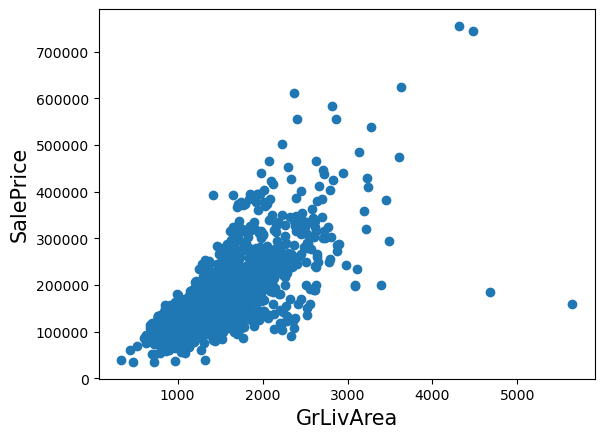

In [86]:
plt.scatter(x = house_df_org['GrLivArea'], y = house_df_org['SalePrice'])
plt.ylabel('SalePrice', fontsize=15)
plt.xlabel('GrLivArea', fontsize=15)
plt.show()

- 일반적으로 주거 공간이 큰 집일수록 가격이 비싸기 때문에 GrLivArea와 SalePrice는 **양의 상관도가 매우 높음**
- 하지만 그림에서 네모로 표시한 **2개의 데이터(outlier)**는 일반적인 관계에서 너무 어긋나 있음 → GrLivArea가 가장 큰데도 가격은 매우 낮음
- **GrLivArea가 4000평방피트 이상임에도 가격이 500,000달러 이하**인 데이터는 모두 이상치로 간주하고 삭제함
- 데이터 변환이 모두 완료된 house_df_ohe에서 대상 데이터를 필터링함
  - GrLivArea와 SalePrice 모두 로그 변환됐으므로 이를 반영한 조건을 생성한 뒤 **불린 인덱싱**으로 대상을 찾음
  - 찾은 데이터의 DataFrame 인덱스와 `drop()`으로 해당 데이터를 삭제함

In [87]:
# GrLivArea와 SalePrice 모두 로그 변환됐으므로 이를 반영한 조건 생성.
cond1 = house_df_ohe['GrLivArea'] > np.log1p(4000)
cond2 = house_df_ohe['SalePrice'] < np.log1p(500000)
outlier_index = house_df_ohe[cond1 & cond2].index

print('이상치 레코드 index :', outlier_index.values)
print('이상치 삭제 전 house_df_ohe shape:', house_df_ohe.shape)

# DataFrame의 인덱스를 이용해 이상치 레코드 삭제.
house_df_ohe.drop(outlier_index, axis=0, inplace=True)
print('이상치 삭제 후 house_df_ohe shape:', house_df_ohe.shape)

이상치 레코드 index : [ 523 1298]
이상치 삭제 전 house_df_ohe shape: (1460, 270)
이상치 삭제 후 house_df_ohe shape: (1458, 270)


- 레코드 인덱스 **523, 1298**이 대상이며 두 개의 데이터를 삭제해 전체 레코드는 **1460개 → 1458개**로 줄어듦
- 업데이트된 house_df_ohe 기반으로 피처/타깃 데이터 세트를 다시 생성하고, print_best_params()로 릿지와 라쏘 모델의 최적화를 수행하고 결과를 출력함

In [88]:
y_target = house_df_ohe['SalePrice']
X_features = house_df_ohe.drop('SalePrice', axis=1, inplace=False)
X_train, X_test, y_train, y_test = train_test_split(X_features, y_target, test_size=0.2,
                                                    random_state=156)

ridge_params = { 'alpha':[0.05, 0.1, 1, 5, 8, 10, 12, 15, 20] }
lasso_params = { 'alpha':[0.001, 0.005, 0.008, 0.05, 0.03, 0.1, 0.5, 1, 5, 10] }
print_best_params(ridge_reg, ridge_params)
print_best_params(lasso_reg, lasso_params)

Ridge 5 CV 시 최적 평균 RMSE 값:0.1125, 최적 alpha:{'alpha': 8}
Lasso 5 CV 시 최적 평균 RMSE 값:0.1122, 최적 alpha:{'alpha': 0.001}


- 단 두 개의 이상치 데이터만 제거했는데 **예측 수치가 매우 크게 향상**됨
  - 릿지의 최적 alpha 값은 **12 → 8**, 평균 RMSE **0.1275 → 0.1125**
  - 라쏘의 평균 RMSE **0.1252 → 0.1122**
  - 라쏘 모델의 경우 RMSE가 약 0.128에서 약 0.114로 매우 낮아짐 
  - 웬만큼 하이퍼 파라미터 튜닝을 해도 이 정도의 수치 개선은 어려움 → GrLivArea 속성이 회귀 모델에서 차지하는 영향도가 크기에 이 이상치를 개선하는 것이 성능 개선에 큰 의미를 가짐
- 이상치를 찾는 것은 쉽지 않지만, **회귀에 중요한 영향을 미치는 피처를 위주로 이상치 데이터를 찾으려는 노력**은 중요함
- 보통 데이터 가공은 알고리즘 적용 이전에 수행하지만, 알고리즘 적용 이전에 완벽하게 선처리하라는 의미는 아님
  - 일단 대략의 데이터 가공과 모델 최적화를 수행한 뒤 다시 이에 기반한 여러 가지 기법의 데이터 가공과 하이퍼 파라미터 기반의 모델 최적화를 **반복적으로 수행**하는 것이 바람직한 머신러닝 모델 생성 과정임



### 회귀 트리 모델 학습/예측/평가 
- 회귀 트리로 회귀 모델을 만듦 → XGBoost는 **XGBRegressor**, LightGBM은 **LGBMRegressor** 클래스 이용
- 두 모델 모두 수행 시간이 오래 걸릴 수 있으므로 하이퍼 파라미터 설정을 미리 적용한 상태로 **5 폴드 세트에 대한 평균 RMSE** 값을 구함

In [89]:
from xgboost import XGBRegressor

xgb_params = {'n_estimators':[1000]}
xgb_reg = XGBRegressor(n_estimators=1000, learning_rate=0.05, colsample_bytree=0.5, subsample=0.8)
print_best_params(xgb_reg, xgb_params)

XGBRegressor 5 CV 시 최적 평균 RMSE 값:0.1197, 최적 alpha:{'n_estimators': 1000}


- XGBoost 회귀 트리의 5 폴드 세트 평균 RMSE는 약 **0.1197** → 이번에는 LightGBM 회귀 트리를 적용함

In [90]:
from lightgbm import LGBMRegressor

lgbm_params = {'n_estimators':[1000]}
lgbm_reg = LGBMRegressor(n_estimators=1000, learning_rate=0.05, num_leaves=4,
                         subsample=0.6, colsample_bytree=0.4, reg_lambda=10, n_jobs=-1)
print_best_params(lgbm_reg, lgbm_params)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002188 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3155
[LightGBM] [Info] Number of data points in the train set: 1166, number of used features: 171
[LightGBM] [Info] Start training from score 12.021352
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001057 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3167
[LightGBM] [Info] Number of data points in the train set: 1166, number of used features: 168
[LightGBM] [Info] Start training from score 12.023516
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM]

- LightGBM의 5 폴드 세트 평균 RMSE는 약 **0.1179**
- 이 모델의 피처 중요도 시각화 



### 회귀 모델의 예측 결과 혼합을 통한 최종 예측 
- 개별 회귀 모델의 예측 결괏값을 **혼합**해 이를 기반으로 최종 회귀 값을 예측함
- 예: A 모델 예측값의 40%, B 모델 예측값의 60%를 더해 최종 회귀 값으로 예측
  - A = [100, 80, 60], B = [120, 80, 50] → 최종 = [100\*0.4 + 120\*0.6, 80\*0.4 + 80\*0.6, 60\*0.4 + 50\*0.6] = **[112, 80, 54]**
- 앞에서 구한 **릿지 모델과 라쏘 모델**을 혼합함
- 최종 혼합 모델, 개별 모델의 RMSE 값을 출력하는 `get_rmse_pred()` 함수를 생성하고 개별 모델과 최종 혼합 모델의 RMSE를 구함

In [92]:
def get_rmse_pred(preds):
    for key in preds.keys():
        pred_value = preds[key]
        mse = mean_squared_error(y_test, pred_value)
        rmse = np.sqrt(mse)
        print('{0} 모델의 RMSE: {1}'.format(key, rmse))

# 개별 모델의 학습
ridge_reg = Ridge(alpha=8)
ridge_reg.fit(X_train, y_train)
lasso_reg = Lasso(alpha=0.001)
lasso_reg.fit(X_train, y_train)
# 개별 모델 예측
ridge_pred = ridge_reg.predict(X_test)
lasso_pred = lasso_reg.predict(X_test)

# 개별 모델 예측값 혼합으로 최종 예측값 도출
pred = 0.4 * ridge_pred + 0.6 * lasso_pred
preds = {'최종 혼합': pred,
         'Ridge': ridge_pred,
         'Lasso': lasso_pred}

#최종 혼합 모델, 개별 모델의 RMSE 값 출력
get_rmse_pred(preds)

최종 혼합 모델의 RMSE: 0.10006075517615196
Ridge 모델의 RMSE: 0.10340697165289361
Lasso 모델의 RMSE: 0.10024171179335342


- 최종 혼합 모델의 RMSE가 개별 모델보다 성능 면에서 **약간 개선**됨
- 릿지 예측값에 0.4, 라쏘 예측값에 0.6을 곱한 뒤 더함 → **0.4나 0.6을 정하는 특별한 기준은 없음**, 두 개 중 성능이 조금 좋은 쪽에 가중치를 약간 더 둠
- 이번에는 **XGBoost와 LightGBM**을 혼합해 결과를 살펴봄

In [93]:
xgb_reg = XGBRegressor(n_estimators=1000, learning_rate=0.05,
                       colsample_bytree=0.5, subsample=0.8)
lgbm_reg = LGBMRegressor(n_estimators=1000, learning_rate=0.05, num_leaves=4,
                         subsample=0.6, colsample_bytree=0.4, reg_lambda=10, n_jobs=-1)
xgb_reg.fit(X_train, y_train)
lgbm_reg.fit(X_train, y_train)
xgb_pred = xgb_reg.predict(X_test)
lgbm_pred = lgbm_reg.predict(X_test)

pred = 0.5 * xgb_pred + 0.5 * lgbm_pred
preds = {'최종 혼합': pred,
         'XGBM': xgb_pred,
         'LGBM': lgbm_pred}

get_rmse_pred(preds)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000888 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3174
[LightGBM] [Info] Number of data points in the train set: 1166, number of used features: 172
[LightGBM] [Info] Start training from score 12.025343
최종 혼합 모델의 RMSE: 0.10375897063342876
XGBM 모델의 RMSE: 0.11041203703289201
LGBM 모델의 RMSE: 0.10363891833477148


- XGBoost와 LightGBM의 혼합 모델 RMSE가 개별 모델의 RMSE보다 **조금 향상**됨

### 스태킹 앙상블 모델을 통한 회귀 예측 
- 4장 분류에서 소개한 **스태킹 모델**을 회귀에도 적용할 수 있음
- 스태킹 모델은 두 종류의 모델이 필요함
  1. 개별적인 **기반 모델**
  2. 이 개별 기반 모델의 예측 데이터를 학습 데이터로 만들어서 학습하는 **최종 메타 모델**
- 핵심: 여러 개별 모델의 예측 데이터를 각각 스태킹 형태로 결합해 최종 메타 모델의 학습용 피처 데이터 세트와 테스트용 피처 데이터 세트를 만드는 것
- 최종 메타 모델이 학습할 피처 데이터 세트 = 원본 학습 피처 세트로 학습한 개별 모델의 예측값을 스태킹 형태로 결합한 것
- 개별 모델을 스태킹 모델로 제공하기 위해 데이터 세트를 생성하는 **`get_stacking_base_datasets()`**

In [94]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error

# 개별 기반 모델에서 최종 메타 모델이 사용할 학습 및 테스트용 데이터를 생성하기 위한 함수.
def get_stacking_base_datasets(model, X_train_n, y_train_n, X_test_n, n_folds ):
    # 지정된 n_folds값으로 KFold 생성.
    kf = KFold(n_splits=n_folds, shuffle=False)
    # 추후에 메타 모델이 사용할 학습 데이터 반환을 위한 넘파이 배열 초기화
    train_fold_pred = np.zeros((X_train_n.shape[0], 1 ))
    test_pred = np.zeros((X_test_n.shape[0], n_folds))
    print(model.__class__.__name__, ' model 시작 ')

    for folder_counter, (train_index, valid_index) in enumerate(kf.split(X_train_n)):
        # 입력된 학습 데이터에서 기반 모델이 학습/예측할 폴드 데이터 세트 추출
        print('\t 폴드 세트: ', folder_counter, ' 시작 ')
        X_tr = X_train_n[train_index]
        y_tr = y_train_n[train_index]
        X_te = X_train_n[valid_index]

        # 폴드 세트 내부에서 다시 만들어진 학습 데이터로 기반 모델의 학습 수행.
        model.fit(X_tr, y_tr)
        # 폴드 세트 내부에서 다시 만들어진 검증 데이터로 기반 모델 예측 후 데이터 저장.
        train_fold_pred[valid_index, :] = model.predict(X_te).reshape(-1, 1)
        # 입력된 원본 테스트 데이터를 폴드 세트 내 학습된 기반 모델에서 예측 후 데이터 저장.
        test_pred[:, folder_counter] = model.predict(X_test_n)

    # 폴드 세트 내에서 원본 테스트 데이터를 예측한 데이터를 평균하여 테스트 데이터로 생성
    test_pred_mean = np.mean(test_pred, axis=1).reshape(-1, 1)

    # train_fold_pred는 최종 메타 모델이 사용하는 학습 데이터, test_pred_mean은 테스트 데이터
    return train_fold_pred, test_pred_mean

- `get_stacking_base_datasets()`는 인자로 개별 기반 모델, 그리고 원래 사용되는 학습 데이터와 테스트용 피처 데이터를 입력받음
- 함수 내에서 개별 모델이 **K-폴드 세트로 설정된 폴드 세트 내부에서 원본의 학습 데이터를 다시 추출**해 학습과 예측을 수행한 뒤 그 결과를 저장함 → 저장된 예측 데이터는 추후 **메타 모델의 학습 피처 데이터 세트**로 이용됨
- 또한 폴드 세트 내부 학습 데이터로 학습된 개별 모델이 인자로 입력된 **원본 테스트 데이터를 예측한 뒤, 예측 결과를 평균**해 테스트 데이터로 생성함
- `get_stacking_base_datasets()`를 모델별로 적용해 메타 모델이 사용할 학습/테스트 피처 데이터 세트를 추출함
- 적용할 개별 모델: **릿지, 라쏘, XGBoost, LightGBM(책 표기 'LightGMB')** 총 4개

In [95]:

# get_stacking_base_datasets( )는 넘파이 ndarray를 인자로 사용하므로 DataFrame을 넘파이로 변환.
X_train_n = X_train.values
X_test_n = X_test.values
y_train_n = y_train.values

# 각 개별 기반(Base) 모델이 생성한 학습용/테스트용 데이터 반환.
ridge_train, ridge_test = get_stacking_base_datasets(ridge_reg, X_train_n, y_train_n, X_test_n, 5)
lasso_train, lasso_test = get_stacking_base_datasets(lasso_reg, X_train_n, y_train_n, X_test_n, 5)
xgb_train, xgb_test = get_stacking_base_datasets(xgb_reg, X_train_n, y_train_n, X_test_n, 5)
lgbm_train, lgbm_test = get_stacking_base_datasets(lgbm_reg, X_train_n, y_train_n, X_test_n, 5)

Ridge  model 시작 
	 폴드 세트:  0  시작 
	 폴드 세트:  1  시작 
	 폴드 세트:  2  시작 
	 폴드 세트:  3  시작 
	 폴드 세트:  4  시작 
Lasso  model 시작 
	 폴드 세트:  0  시작 
	 폴드 세트:  1  시작 
	 폴드 세트:  2  시작 
	 폴드 세트:  3  시작 
	 폴드 세트:  4  시작 
XGBRegressor  model 시작 
	 폴드 세트:  0  시작 
	 폴드 세트:  1  시작 
	 폴드 세트:  2  시작 
	 폴드 세트:  3  시작 
	 폴드 세트:  4  시작 
LGBMRegressor  model 시작 
	 폴드 세트:  0  시작 
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000730 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2924
[LightGBM] [Info] Number of data points in the train set: 932, number of used features: 156
[LightGBM] [Info] Start training from score 12.035561
	 폴드 세트:  1  시작 
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000428 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=tru

- 각 개별 모델이 반환하는 학습용 피처 데이터와 테스트용 피처 데이터 세트를 결합해 최종 메타 모델에 적용함
- 메타 모델은 별도의 **라쏘 모델**을 이용하며, 최종적으로 예측 및 RMSE를 측정함

In [96]:
# 개별 모델이 반환한 학습 및 테스트용 데이터 세트를 스태킹 형태로 결합.
Stack_final_X_train = np.concatenate((ridge_train, lasso_train, xgb_train, lgbm_train), axis=1)
Stack_final_X_test = np.concatenate((ridge_test, lasso_test,xgb_test, lgbm_test), axis=1)

# 최종 메타 모델은 라쏘 모델을 적용.
meta_model_lasso = Lasso(alpha=0.0005)

# 개별 모델 예측값을 기반으로 새롭게 만들어진 학습/테스트 데이터로 메타 모델 예측 및 RMSE 측정.
meta_model_lasso.fit(Stack_final_X_train, y_train)
final = meta_model_lasso.predict(Stack_final_X_test)
mse = mean_squared_error(y_test, final)
rmse = np.sqrt(mse)
print('스태킹 회귀 모델의 최종 RMSE 값은:', rmse)

스태킹 회귀 모델의 최종 RMSE 값은: 0.09718403678879947


- 스태킹 회귀 모델 적용 결과 테스트 데이터 세트에서 RMSE가 약 **0.0979**로 현재까지 **가장 좋은 성능 평가**를 보여줌
- 스태킹 모델은 분류뿐만 아니라 **회귀에서 특히 효과적으로 사용될 수 있는 모델**임

## 11 정리 

- **선형 회귀**: 실제값과 예측값의 차이인 오류를 최소로 줄일 수 있는 선형 함수를 찾아 이 선형 함수에 독립변수(피처)를 입력해 종속변수(타깃값, 예측값)를 예측하는 것임
  - 최적의 선형 함수를 찾기 위해 실제값과 예측값 차이의 제곱을 회귀 계수 W를 변수로 하는 **비용 함수**로 만들고, 이 비용 함수가 최소화되는 W의 값을 찾아 선형 함수를 도출함
  - 비용 함수를 최소화하는 방법으로 **경사 하강법**을 소개함 → 비용 함수의 최적화 기법은 머신러닝 전반에 걸쳐서 매우 중요한 개념 중 하나임
- 실제값과 예측값의 차이를 최소화하는 것에만 초점을 맞춘 단순 선형 회귀는 학습 데이터에 **과적합**되는 문제를 수반할 가능성이 높음
  - 이를 해결하기 위해 **규제(Regularization)**를 선형 회귀에 도입함
  - 대표적인 규제 선형 회귀: **L2 규제 → 릿지**, **L1 규제 → 라쏘**, **L1 + L2 규제 결합 → 엘라스틱넷**
  - 일반적으로 선형 회귀는 이들 규제 선형 회귀를 많이 사용함
- **로지스틱 회귀**: 선형 회귀를 분류에 적용한 대표적인 모델 → 이름은 회귀이지만 실제로는 **분류**를 위한 알고리즘임
  - 선형 함수 대신 최적의 **시그모이드 함수**를 도출하고, 독립변수(피처)를 이 시그모이드 함수에 입력해 반환된 결과를 확률값으로 변환해 예측 레이블을 결정함
  - 매우 뛰어난 분류 알고리즘이며, 특히 **이진 분류나 희소 행렬로 표현되는 텍스트 기반의 분류**에서 높은 예측 성능을 나타냄
- **회귀 트리**: 최적의 선형(또는 비선형) 함수를 찾는 대신 회귀 트리를 이용해 예측하는 방법
  - 분류 트리와 크게 다르지 않으나 리프 노드에서 예측 결정 값을 만드는 과정에 차이가 있음 → 리프 노드에 속한 데이터 값의 **평균값**을 구해 회귀 예측값을 계산함
  - 결정 트리, 랜덤 포레스트, GBM, XGBoost, LightGBM 모두 회귀 트리를 이용해 회귀를 수행하는 방법을 제공함
- 선형 회귀는 **데이터 값의 분포도와 인코딩 방법**에 많은 영향을 받을 수 있음
  - 데이터 값의 분포도가 정규 분포와 같이 종 모양의 형태를 선호하며, 특히 **타깃값의 분포도가 왜곡(Skew)되지 않고 정규 분포 형태**로 되어야 예측 성능을 저하시키지 않음 → 왜곡된 분포도를 가지고 있을 때 일반적으로 **로그 변환**을 적용하는 것이 유용함
  - 데이터 세트에 카테고리형 데이터가 있을 경우 레이블 인코딩을 통한 숫자형 변환보다는 **원-핫 인코딩**으로 변환해줘야 함
  - 회귀 트리의 경우 인코딩 방식에 크게 영향을 받지는 않음
- 두 가지 예제를 실습해 보면서 데이터 정제와 변환, 선형 회귀/회귀 트리의 최적화를 통해 어떻게 회귀 모델을 향상시키는지 실습함
  - 특히 **스태킹 모델을 회귀에 적용**해 훌륭한 예측 성능을 도출함